# VenaSteward - analysis notebook
Mahir Jain | SSETC Hackathon 2026 | AI in Healthcare

Everything the dashboard shows comes from this notebook. It goes in this order:

1. Load the data
2. Find the central lines
3. Take a snapshot of the patient at 08:00 every morning
4. Apply the idle-line rule
5. Check that no future data leaks into a morning
6. Test if a model can beat a simple dose rule
7. Save small tables for the dashboard

**Data:** MIMIC-IV Clinical Database Demo v2.2. 100 de-identified ICU patients from one hospital in Boston, free on PhysioNet with no login (https://physionet.org/content/mimic-iv-demo/2.2/). The outputs below are already saved. To rerun, download the ZIP from that page and unzip it next to this notebook.

Licence: Open Database License v1.0. `morning_list.csv`, which this notebook makes, is shared under the same licence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = "mimic-iv-clinical-database-demo-2.2/"
HOUR = pd.Timedelta(hours=1)
plt.rcParams["font.family"] = "serif"

icu = pd.read_csv(DATA + "icu/icustays.csv.gz", parse_dates=["intime", "outtime"])
proc = pd.read_csv(DATA + "icu/procedureevents.csv.gz", parse_dates=["starttime", "endtime"])
inputs = pd.read_csv(DATA + "icu/inputevents.csv.gz", parse_dates=["starttime", "endtime"])
adm = pd.read_csv(DATA + "hosp/admissions.csv.gz", parse_dates=["deathtime"])
micro = pd.read_csv(DATA + "hosp/microbiologyevents.csv.gz", parse_dates=["chartdate", "charttime"])

print(len(icu), "ICU stays |", icu.subject_id.nunique(), "patients")

140 ICU stays | 100 patients


## Item IDs
MIMIC stores everything as item numbers. I looked these up in the `d_items` table of the demo.

Doses of different blood pressure drugs are combined into one number, the norepinephrine equivalent (Goradia et al. 2021): norepinephrine + epinephrine + phenylephrine / 10 + dopamine / 100 + vasopressin x 2.5. All in mcg/kg/min except vasopressin, which is in units/min. MIMIC charts vasopressin in units/hour, so I divide by 60.

In [2]:
CVC = {224263: "Multi lumen", 224267: "Introducer", 224268: "Trauma line"}

# norepinephrine, epinephrine, phenylephrine, dopamine, vasopressin -> factor to norepinephrine equivalent
VASO = {221906: 1, 221289: 1, 221749: 1 / 10, 221662: 1 / 100, 222315: 2.5 / 60}
INOTROPE = [221653, 221986]  # dobutamine, milrinone
TPN = [225916, 225917]  # TPN with lipids, TPN without lipids

all_ids = list(CVC) + list(VASO) + INOTROPE + TPN

## 1. Central lines
Version one only looks at temporary central lines (multi lumen, introducer, trauma line). PICCs, dialysis lines and ports are left out because people keep them for different reasons.

A line record stops when the patient leaves the ICU, so I cut every line at ICU discharge.

In [3]:
lines = proc[proc.itemid.isin(CVC)].merge(icu[["stay_id", "outtime"]], on="stay_id")
lines["start"] = lines.starttime
lines["end"] = lines[["endtime", "outtime"]].min(axis=1)
lines = lines[lines.end > lines.start].sort_values("start").reset_index(drop=True)

lines["line_id"] = ["CVC-%02d" % (i + 1) for i in range(len(lines))]
lines["type"] = lines.itemid.map(CVC)
lines["site"] = lines.location.fillna("Not recorded").str.replace(".", "", regex=False)
lines["femoral"] = lines.site.str.contains("Femoral")
lines["days"] = (lines.end - lines.start) / pd.Timedelta(days=1)
lines["left_icu_with_line"] = (lines.outtime - lines.end) <= HOUR

print(len(lines), "central lines |", lines.subject_id.nunique(), "patients |", lines.stay_id.nunique(), "ICU stays")
print("line-days in total:", round(lines.days.sum(), 1), "| median per line:", round(lines.days.median(), 2), "days")
print("lines still in when the patient left the ICU:", lines.left_icu_with_line.sum())
lines.site.value_counts()

60 central lines | 43 patients | 50 ICU stays
line-days in total: 190.7 | median per line: 2.28 days
lines still in when the patient left the ICU: 27


site
Not recorded        25
Right IJ            21
Left Subclavian      4
Right Femoral        4
Left IJ              3
Left Femoral         2
Right Subclavian     1
Name: count, dtype: int64

## 2. Support that needs a central line
These are the "tracked reasons" for a line: blood pressure drugs (vasopressors), heart drugs (inotropes) and IV nutrition (TPN). MIMIC writes a new row every time a rate changes, so one infusion is many rows. That is fine here, I only ever ask "was something running at this time?".

In [4]:
support = inputs[inputs.itemid.isin(all_ids) & (inputs.endtime > inputs.starttime)].copy()
support["kind"] = np.where(support.itemid.isin(TPN), "tpn", "vasoactive")
support["nee"] = support.rate * support.itemid.map(VASO).fillna(0)  # inotropes and TPN count as 0 dose

died = adm.set_index("hadm_id").deathtime

line_stays = set(lines.stay_id)
vaso_stays = set(support[support.kind == "vasoactive"].stay_id)
print("line stays that also had support:", len(line_stays & set(support.stay_id)), "of", len(line_stays))

line stays that also had support: 37 of 50


## 3. The 08:00 snapshot
Every morning at 08:00 the ICU team does its round. For each patient I build what the team would know at that moment, **using only data recorded up to 08:00**. The label (what happens next) is kept in a separate function, so it can never sneak into the features.

In [5]:
def mornings(intime, outtime):
    """all 08:00 rounds during an ICU stay"""
    t = intime.normalize() + pd.Timedelta(hours=8)
    if t <= intime:
        t += pd.Timedelta(days=1)
    out = []
    while t < outtime:
        out.append(t)
        t += pd.Timedelta(days=1)
    return out


def running(rows, t):
    return rows[(rows.starttime <= t) & (rows.endtime > t)]


def features(sup, t):
    """what the team knows at time t (only uses rows that had started by t)"""
    vaso = sup[sup.kind == "vasoactive"]
    now = running(vaso, t)
    ended = sup[sup.endtime <= t]
    dose_now = now.nee.sum()
    return {
        "vaso_on": len(now) > 0,
        "tpn_on": len(running(sup[sup.kind == "tpn"], t)) > 0,
        "dose_now": dose_now,
        "dose_change_6h": dose_now - running(vaso, t - 6 * HOUR).nee.sum(),
        "dose_change_24h": dose_now - running(vaso, t - 24 * HOUR).nee.sum(),
        "n_drugs": now.itemid.nunique(),
        "last_support_end": ended.endtime.max() if len(ended) else pd.NaT,
    }


def label(sup, t, outtime, died_in_icu):
    """1 if blood pressure support is off from t+24h and stays off for 24h more.
    Support that ends because the patient died does not count."""
    vaso = sup[sup.kind == "vasoactive"]
    w0, w1 = t + 24 * HOUR, t + 48 * HOUR
    end = min(w1, outtime)
    if end > w0 and ((vaso.starttime < end) & (vaso.endtime > w0)).any():
        return 0
    if outtime >= w1:
        return 1
    return 0 if died_in_icu else 1


rows = []
for stay in sorted(line_stays | vaso_stays):
    s = icu[icu.stay_id == stay].iloc[0]
    sup = support[support.stay_id == stay]
    died_in_icu = pd.notna(died[s.hadm_id]) and died[s.hadm_id] <= s.outtime + 12 * HOUR
    for i, t in enumerate(mornings(s.intime, s.outtime)):
        f = features(sup, t)
        f.update(stay_id=stay, subject_id=s.subject_id, time=t, icu_day=i + 1)
        f["y"] = label(sup, t, s.outtime, died_in_icu) if f["vaso_on"] else np.nan
        rows.append(f)

mornings_df = pd.DataFrame(rows)
print(len(mornings_df), "patient-mornings |", mornings_df.vaso_on.sum(), "of them on blood pressure support")

343 patient-mornings | 118 of them on blood pressure support


## 4. The idle-line rule
For every line that is in at 08:00:
- **idle hours** = hours since the last tracked reason stopped (or since the line went in, if there never was one). It is 0 while support is running.
- **flag** if idle hours >= 24. The flag does not say "remove the line". It says "this line needs a decision today".

I also count three infection exposure factors from the guidelines: femoral site, TPN running and more than one central line. It is just a count, not a risk score.

In [6]:
line_rows = []
for m in mornings_df[mornings_df.stay_id.isin(line_stays)].itertuples():
    in_place = lines[(lines.stay_id == m.stay_id) & (lines.start <= m.time) & (lines.end > m.time)]
    for ln in in_place.itertuples():
        if m.vaso_on or m.tpn_on:
            idle = 0.0
        else:
            since = ln.start if pd.isna(m.last_support_end) else max(ln.start, m.last_support_end)
            idle = (m.time - since) / HOUR
        reasons = [r for r, on in [("Blood pressure drugs running", m.vaso_on), ("TPN running", m.tpn_on)] if on]
        exposure = [f for f, on in [("Femoral site", ln.femoral), ("TPN running", m.tpn_on),
                                    ("More than one central line", len(in_place) > 1)] if on]
        line_rows.append({
            "stay_id": m.stay_id, "time": m.time, "icu_day": m.icu_day, "line_id": ln.line_id,
            "type": ln.type, "site": ln.site, "line_day": round((m.time - ln.start) / pd.Timedelta(days=1), 1),
            "idle_hours": round(idle), "flag": idle >= 24, "reasons": "; ".join(reasons),
            "exposure": "; ".join(exposure), "n_exposure": len(exposure), "dose_now": round(m.dose_now, 3),
        })

snap = pd.DataFrame(line_rows)
flagged = snap.flag.sum()
print("line-mornings checked:", len(snap))
print("flagged:", flagged, f"({flagged / len(snap):.0%})")
print("lines flagged at least once:", snap[snap.flag].line_id.nunique(), "of", len(lines))

line-mornings checked: 192
flagged: 63 (33%)
lines flagged at least once: 28 of 60


**Sanity check against the papers.** Published studies find 15% to 28% of central line days are idle. My rule flags a bit more, which makes sense: it cannot see every reason (difficult veins, other drips), so it should be read as an upper estimate. That is also why the app asks the doctor for a reason instead of telling them what to do.

## 5. Leakage check
The most common way these projects cheat by accident is using future data. So I rebuild every morning with **all data after 08:00 deleted** and check that the features come out exactly the same.

In [7]:
cols = ["vaso_on", "tpn_on", "dose_now", "dose_change_6h", "dose_change_24h", "n_drugs", "last_support_end"]
problems = 0
for m in mornings_df.itertuples():
    sup = support[(support.stay_id == m.stay_id) & (support.starttime <= m.time)].copy()
    sup["endtime"] = sup.endtime.clip(upper=m.time + pd.Timedelta(minutes=1))  # nothing known after 08:00
    cut = features(sup, m.time)
    full = mornings_df.loc[m.Index, cols].to_dict()
    for c in cols:
        a, b = full[c], cut[c]
        same = (pd.isna(a) and pd.isna(b)) or (a == b) or (isinstance(a, float) and np.isclose(a, b))
        problems += not same
print("mornings checked:", len(mornings_df), "| features that changed:", problems)

mornings checked: 343 | features that changed: 0


## 6. Can a model beat a simple rule?
The idea: a line usually stops being needed when blood pressure support ends. If the team knew a day early, they could plan.

- **Question:** at 08:00, will blood pressure support be off from tomorrow's round and stay off for 24 more hours?
- **Model:** logistic regression on 4 features (dose now, dose change over 6h and 24h, number of drugs).
- **Explainable:** for every forecast I also save the reasons behind it. In a logistic regression each feature adds (weight x scaled value) to the score, so the biggest pushes are the reasons.
- **Rule to beat:** just rank patients by current dose, lowest first. No training.
- **Testing:** leave one patient out. Every patient is scored by a model that never saw them.
- **95% interval:** resample whole patients 2,000 times.

In [8]:
data = mornings_df[mornings_df.vaso_on].reset_index(drop=True)
X = data[["dose_now", "dose_change_6h", "dose_change_24h", "n_drugs"]]
y = data.y.astype(int)
patients = data.subject_id

def describe(feature, value):
    """plain words for one feature value (doses in mcg/kg/min)"""
    if feature == "dose_now":
        return f"dose now {value:.2f}"
    if feature == "n_drugs":
        return "1 drug running" if value == 1 else f"{int(value)} drugs running"
    hours = "6 h" if feature == "dose_change_6h" else "24 h"
    return f"dose change over {hours} {value:+.2f}"


prob = np.zeros(len(data))
why = [""] * len(data)
for p in patients.unique():
    test = patients == p
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
    model.fit(X[~test], y[~test])
    prob[test] = model.predict_proba(X[test])[:, 1]
    # reasons: each feature's push = weight x scaled value
    push = model[0].transform(X[test]) * model[1].coef_[0]
    for row, i in enumerate(np.where(test)[0]):
        top = np.argsort(-np.abs(push[row]))[:3]
        towards = [describe(X.columns[j], X.iloc[i, j]) for j in top if push[row, j] > 0]
        against = [describe(X.columns[j], X.iloc[i, j]) for j in top if push[row, j] < 0]
        parts = []
        if towards:
            parts.append("for ending: " + ", ".join(towards))
        if against:
            parts.append("against: " + ", ".join(against))
        why[i] = ". ".join(parts)

rule = -data.dose_now  # lower dose = more likely to come off


def interval(score, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    ids = patients.unique()
    out = []
    for _ in range(n):
        pick = rng.choice(ids, len(ids))
        idx = np.concatenate([np.where(patients == p)[0] for p in pick])
        if y[idx].nunique() == 2:
            out.append(roc_auc_score(y[idx], np.asarray(score)[idx]))
    low, high = np.percentile(out, [2.5, 97.5])
    return f"{low:.2f} to {high:.2f}"


results = pd.DataFrame({
    "method": ["Rule: lowest dose first", "Logistic regression (4 features)"],
    "AUROC": [roc_auc_score(y, rule), roc_auc_score(y, prob)],
})
results["95% interval"] = [interval(rule), interval(prob)]
print(len(data), "patient-mornings |", y.sum(), "times support ended |", patients.nunique(), "patients")
data["why"] = why
print(data[["dose_now", "y", "why"]].head(5).to_string(index=False))
results.round(2)

118 patient-mornings | 20 times support ended | 26 patients
 dose_now   y                                                                              why
 0.000000 0.0           for ending: dose now 0.00, dose change over 24 h +0.00, 1 drug running
 0.000000 0.0           for ending: dose now 0.00, dose change over 24 h +0.00, 1 drug running
 0.029976 0.0 for ending: dose now 0.03, dose change over 24 h +0.03. against: 2 drugs running
 0.000000 1.0           for ending: dose now 0.00, dose change over 24 h -0.03, 1 drug running
 0.019980 1.0           for ending: dose now 0.02, 1 drug running, dose change over 24 h +0.02


,method,AUROC,95% interval
0,Rule: lowest dose first,0.80,0.70 to 0.93
1,Logistic regression (4 features),0.79,0.68 to 0.92


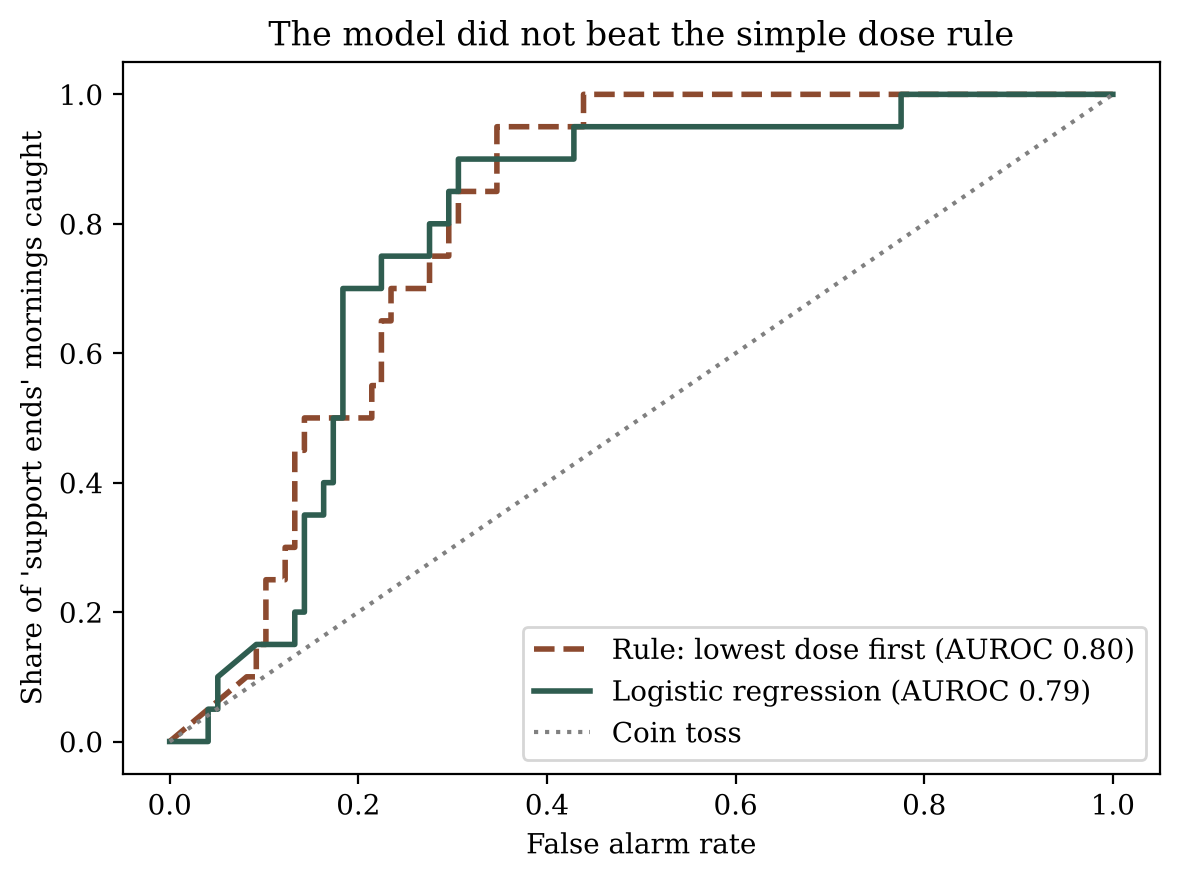

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for score, name, style in [(rule, "Rule: lowest dose first", "--"), (prob, "Logistic regression", "-")]:
    color = "#8C4A2F" if style == "--" else "#2F5D50"
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, style, color=color, lw=2, label=f"{name} (AUROC {roc_auc_score(y, score):.2f})")
ax.plot([0, 1], [0, 1], ":", color="grey", label="Coin toss")
ax.set_xlabel("False alarm rate")
ax.set_ylabel("Share of 'support ends' mornings caught")
ax.set_title("The model did not beat the simple dose rule")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result: the model did not win.** The dose rule scored a little higher and the intervals overlap almost completely, because there are only 20 events. So I can't say the model is worse, but I definitely can't say it adds anything. I'm reporting it as it is. In the app the forecast stays, but it is marked experimental. The first job with the full MIMIC-IV data is to run this test again on far more patients.

## 7. Infections
Do I have enough line infections to train an infection model? Positive blood cultures taken at least 48 hours after a line went in, while it was in or up to 48 hours after:

In [10]:
blood = micro[micro.spec_type_desc.str.contains("BLOOD CULTURE", na=False) & micro.org_name.notna()].copy()
blood["time"] = blood.charttime.fillna(blood.chartdate)
hits = blood.merge(lines[["hadm_id", "start", "end"]], on="hadm_id")
hits = hits[(hits.time >= hits.start + 48 * HOUR) & (hits.time <= hits.end + 48 * HOUR)]
print("possible line infections:", hits.hadm_id.nunique())

possible line infections: 1


One. You can't train anything on one case, so there is no infection model. The app shows the simple exposure count instead and says so.

## 8. Save the table for the dashboard
MIMIC shifts all dates, so stays can't be put on a real calendar. To make the demo look like a real unit I place the stays one after another into 12 beds. Only the bed and the day number are made up, everything clinical is as recorded.

In [11]:
data["forecast"] = pd.qcut(prob, 3, labels=["Unlikely", "Possible", "Likely"]).astype(str)
snap = snap.merge(data[["stay_id", "time", "forecast", "why"]], on=["stay_id", "time"], how="left")

beds = np.zeros(12, dtype=int)  # next free day for each bed
place = {}
for stay, g in snap.groupby("stay_id"):
    b = int(beds.argmin())
    place[stay] = (b + 1, beds[b])
    beds[b] += g.icu_day.max() - g.icu_day.min() + 1
snap["bed"] = snap.stay_id.map(lambda s: place[s][0])
snap["day"] = snap.stay_id.map(lambda s: place[s][1]) + snap.icu_day - snap.groupby("stay_id").icu_day.transform("min") + 1

# short patient codes instead of MIMIC ids
code = {stay: "P%02d" % (i + 1) for i, stay in enumerate(sorted(line_stays))}
snap["patient"] = snap.stay_id.map(code)
snap.drop(columns=["stay_id", "time"]).to_csv("morning_list.csv", index=False)

summary = {
    "lines": len(lines), "patients_with_line": int(lines.subject_id.nunique()),
    "stays_with_line": len(line_stays), "line_days": round(float(lines.days.sum()), 1),
    "line_mornings": len(snap), "flagged": int(flagged), "lines_flagged": int(snap[snap.flag].line_id.nunique()),
    "model_mornings": len(data), "events": int(y.sum()), "model_patients": int(patients.nunique()),
    "rule_auroc": round(float(results.AUROC[0]), 2), "model_auroc": round(float(results.AUROC[1]), 2),
    "rule_interval": results["95% interval"][0], "model_interval": results["95% interval"][1],
    "possible_infections": int(hits.hadm_id.nunique()),
}
print("days in the replay:", snap.day.max())
summary

days in the replay: 26


{'lines': 60,
 'patients_with_line': 43,
 'stays_with_line': 50,
 'line_days': 190.7,
 'line_mornings': 192,
 'flagged': 63,
 'lines_flagged': 28,
 'model_mornings': 118,
 'events': 20,
 'model_patients': 26,
 'rule_auroc': 0.8,
 'model_auroc': 0.79,
 'rule_interval': '0.70 to 0.93',
 'model_interval': '0.68 to 0.92',
 'possible_infections': 1}